## Metadatos

In [ ]:
# Metadatos del Proyecto
from datetime import datetime
AUTOR = "Mgtr. Ronald Osorio"
FECHA_MODIFICACION = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

print(f"Autor: {AUTOR}")
print(f"Última modificación: {FECHA_MODIFICACION}\n" + "-"*40)

Autor: Mgtr. Ronald Osorio
Última modificación: 19/10/2026 01:35:15
----------------------------------------


## Entorno

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Montar Google Drive (te pedirá autorización en ventana emergente)
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/Colab Notebooks/Bd')
from descriptive_analysis import *

In [ ]:
# Configuración del sistema y utilidades
import warnings
warnings.filterwarnings('ignore')

# Configuración de constantes
from sklearn.model_selection import KFold
SEED = 42
N_ITER_TUNING = 75  # <-- AUMENTADO de 30 a 75
kf   = KFold(n_splits=5, shuffle=True, random_state=SEED)

## Df
Asegúrate de estar conectado a Colab

In [ ]:
# Cargar directamente desde tu Drive (Asegúrate de cambiar la ruta si está en una subcarpeta)
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Bd/housing_EDA.csv')
df = df.sample(frac=0.1, random_state=SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Df Final

In [94]:
df.head(3)

,house_age,households,income,population,latitude,longitude,rooms,bedrooms,ocean_dist,price
14278,19.0,463.0,1.8200,1129.0,34.40,-114.47,7650.0,1901.0,inland,80100.0
16224,32.0,274.0,8.7172,769.0,34.16,-118.48,2108.0,309.0,<1h ocean,500001.0
7646,37.0,240.0,4.1731,485.0,34.19,-118.32,1335.0,249.0,<1h ocean,352100.0


In [95]:
df = df[[ 'house_age', 'households', 'income',
          'population',
          'latitude', 'longitude',
          'rooms', 'bedrooms',
          'ocean_dist',
          'price']]

## Preprocesamiento

### Hallazgos Clave
| Objetivos | Descripción | Columnas | Completado |
| :--- | :--- | :--- | :--- |
| 1. Datos Faltantes y Patrones | Sí | bedrooms | P |
| 3. Valores Atípicos (Outliers) | Sí | rooms, bedrooms, population, households, income, price | P |
| 4. Transformación de la Variable Objetivo | Sí | | P |
| 6. Escalado de Datos | Sí | Todas | P |
| 7. Asimetría (Skewness) | Sí | Todas | P |
| 9. Codificación (Relaciones no Lineales y Asociaciones) | Sí | ocean_dist | P |

Prioridades Clave para Regresión

| Factor | Modelos Lineales / Redes Neuronales / KNN | Modelos Basados en Árboles (Random Forest, XGBoost) |
| :--- | :--- | :--- |
| **Escala** | 🚨 **Crítico** (El escalado es obligatorio) | ❌ **Irrelevante** (No se requiere acción) |
| **Asimetría / Sesgo (Skewness)** | 🚨 **Importante** (Mejora el rendimiento) | ❌ **Irrelevante** (No se requiere acción) |
| **Asimetría / Sesgo (Skewness)** | 🚨 **Importante** (Mejora el rendimiento) | ❌ **Irrelevante** (No se requiere acción) |
| **Bimodal / Multimodal** | 🚨 **Importante** (Rompe la normalidad de residuos y predice en el valle vacío) | ❌ **Irrelevante** (No se requiere acción) |
| **Valores Atípicos en Características** | 🚨 **Crítico** (Distorciona líneas y planos) | ❌ **Irrelevante** (Aislados en hojas separadas) |
| **Valores Atípicos en la Variable Objetivo** | 🚨 **Crítico** (Distorciona la función de pérdida) | 🚨 **Crítico** (Arruina las predicciones promedio de las hojas) |

### Separación

In [ ]:
from sklearn.model_selection import train_test_split

# Definición del conjunto de características y variable objetivo
FEATURES = ['house_age', 'households', 'income',
            'rooms', 'bedrooms', 'population',
            'latitude', 'longitude',
            'ocean_dist']
TARGET   = 'price'

# Asignación de datos y variable objetivo
X = df [FEATURES]
y = df [TARGET]

# Dividir el conjunto de datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)

# Reporte
# Tamaño de la partición
print('=== TAMAÑO DE LA PARTICIÓN ===')
print(f'Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}')
print(f'Entrenamiento %: {len(X_train)/len(X)*100:.1f}% | Prueba %: {len(X_test)/len(X)*100:.1f}%')

# Estadísticas de la variable objetivo
print('\n=== DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ===')
print(f'Media      -> Entrenamiento: {y_train.mean():.3f} | Prueba: {y_test.mean():.3f}')
print(f'Desv. Est. -> Entrenamiento: {y_train.std():.3f}  | Prueba: {y_test.std():.3f}')

# Forma de la distribución
print('\n=== PERCENTILES DE LA VARIABLE OBJETIVO ===')
print(pd.DataFrame({
    'Entrenamiento': y_train.quantile([0, .25, .5, .75, 1]),
    'Prueba':        y_test.quantile([0, .25, .5, .75, 1])
}))

# Verificación rápida
print('\n=== VERIFICACIÓN ===')
print('Medias y desviaciones estándar similares → partición representativa')

=== TAMAÑO DE LA PARTICIÓN ===
Entrenamiento: (1634, 9) | Prueba: (409, 9)
Entrenamiento %: 80.0% | Prueba %: 20.0%

=== DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ===
Media      -> Entrenamiento: 213312.782 | Prueba: 209244.787
Desv. Est. -> Entrenamiento: 119164.071  | Prueba: 119430.413

=== PERCENTILES DE LA VARIABLE OBJETIVO ===
      Entrenamiento    Prueba
0.00        27500.0   37500.0
0.25       124625.0  115800.0
0.50       184650.0  182100.0
0.75       275675.0  271300.0
1.00       500001.0  500001.0

=== VERIFICACIÓN ===
Medias y desviaciones estándar similares → partición representativa


### Modificaciones de X_train

#### Duplicados

In [97]:
check_duplicates(X_train, subset = None)


DUPLICATES ANALYSIS
Rows with duplicated None: 0 (0.00%)
✓ No duplicates found


#### Numéricos (Nulos, Valores Atípicos, Escalado)

In [98]:
# Calcular los límites usando los percentiles de y_train
q1, q3 = np.percentile(y_train, [25, 75])
iqr = q3 - q1

# Aplicar el recorte (clip) directamente a y_train
y_train = np.clip(y_train, q1 - 1.5 * iqr, q3 + 1.5 * iqr)

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

# Transformador personalizado para el manejo de valores atípicos mediante IQR
class OutlierClipper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X_arr = np.asarray(X)

        Q1 = np.nanpercentile(X_arr, 25, axis=0)
        Q3 = np.nanpercentile(X_arr, 75, axis=0)
        IQR = Q3 - Q1
        self.lower_ = Q1 - self.factor * IQR
        self.upper_ = Q3 + self.factor * IQR
        return self

    def transform(self, X):
        # Recorta los valores fuera de los límites calculados
        return np.clip(np.asarray(X), self.lower_, self.upper_)

In [100]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer

# NUMÉRICO - LINEAL
num_pipe_linear = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clipper', OutlierClipper(factor=1.5)),
    ('power', PowerTransformer(method='yeo-johnson', standardize=True)) # <-- transforma escala y distribución
])

# NUMÉRICO - ÁRBOLES
num_pipe_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

#### Categóricos (Codificación)

In [101]:
from sklearn.preprocessing import OneHotEncoder

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # codificar
])

#### Conversión a Columnas Categóricas
No requerido

#### Ingeniería de Características

Simple

In [ ]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X['rooms_per_household'] = X['rooms'] / X['households']
        X['bedrooms_per_room'] = X['bedrooms'] / X['rooms']
        X['pop_per_household'] = X['population'] / X['households']
        X['household_per_population'] = X['households'] / X['population']

        return X

    def get_feature_names_out(self, input_features=None):  # <-- agregar esto
        return None  #

Complejo

In [103]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

geo_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), # imputar coordenadas primero
    ('scaler', StandardScaler()),                  # escalar para PCA
    ('pca', PCA(n_components=2, random_state=SEED))                  # crear nuevas variables
])

#### Columnas

In [104]:
num_cols = ['households', 'income', # originales
            'rooms_per_household', 'bedrooms_per_room','pop_per_household', 'household_per_population' ] # nuevas
cat_cols = ['ocean_dist']
pca_cols = ['latitude', 'longitude']

#### Todas las Transformaciones

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor_linear = Pipeline([                 # <-- Se usa pipeline porque se tiene feature engineering. Si no estuviera, se usaría ColumnTransformer
    ('feature_eng', FeatureEngineer()),          # <-- PRIMERO
    ('col_transform', ColumnTransformer([
        ('num', num_pipe_linear, num_cols),
        ('cat', cat_pipe, cat_cols),
        ('geo', geo_pipe, pca_cols)
    ], remainder='drop')) # <-- evita duplicaciones
])

preprocessor_tree = Pipeline([                   # <-- Se usa pipeline porque se tiene feature engineering. Si no estuviera, se usaría ColumnTransformer
    ('feature_eng', FeatureEngineer()),          # <-- PRIMERO
    ('col_transform', ColumnTransformer([
        ('num', num_pipe_tree, num_cols),
        ('cat', cat_pipe, cat_cols),
        ('geo', geo_pipe, pca_cols)
    ], remainder='drop')) # <-- evita duplicaciones
])


# Algoritmos

## Pipeline Integrado para Benchmarking, Optimización y Validación de Robustez

### Configuración del Entorno y Modelos

#### Definición del Espacio de Búsqueda (PARAM_DISTS)

In [106]:
from scipy.stats import randint, uniform, loguniform

PARAM_DISTS = {

    # 1. Regresión lineal (base y regularizada)
    'Linear Regression': {},  # regresión lineal múltiple si X tiene >1 características

    'Ridge': {
        'regressor__model__alpha': loguniform(0.1, 10) #*** < con todos los parámetros: comenzar con rangos amplios, luego reducir alrededor del mejor parámetro
    },

    'Lasso': {
        'regressor__model__alpha': loguniform(1e-4, 10)
    },

    'ElasticNet': {
        'regressor__model__alpha': loguniform(1e-4, 10),
        'regressor__model__l1_ratio': uniform(0.0, 1.0)
    },

    # 2. Regresión polinomial
    'Polynomial Reg (deg 2)': {
        'regressor__poly__degree': [2, 3],
        'regressor__model__alpha': np.logspace(1, 2, 20)
    },

    # 3. Modelos basados en kernels y distancias
    'SVR': {
        'regressor__model__C': loguniform(1, 20), # Bajado de 1000 a 100
        'regressor__model__gamma': loguniform(1e-4, 1e-2), # Rango más estrecho
        'regressor__model__epsilon': uniform(0.01, 0.5)  # Más sensible
    },

    'KNN': {
        'regressor__model__n_neighbors': randint(5, 100), # Para regresión probar n alto
        'regressor__model__weights': ['uniform', 'distance'],
        'regressor__model__metric': ['minkowski'], # Minkowski combina Manhattan y Euclidean. Si no sabes cuál de las dos usar, usa minkowski
        'regressor__model__p': [1, 2]
    },

    # 4. Redes neuronales
    'Neural Network': {
        'regressor__model__hidden_layer_sizes': [(128, 128, 64),
                                       (256, 128, 64)
        ],
        'regressor__model__activation': ['tanh'],
        'regressor__model__alpha': loguniform(1e-3, 0.1),
        'regressor__model__learning_rate': ['adaptive'],
        'regressor__model__learning_rate_init': loguniform(1e-3, 0.01)
    },


    # 5. Árbol de decisión
    'Decision Tree': {
        'regressor__model__max_depth': randint(3, 10),
        'regressor__model__min_samples_split': randint(5, 40),
        'regressor__model__min_samples_leaf': randint(2, 20),
        'regressor__model__max_features': ['sqrt', 'log2', None]
    },

    # 6. Ensambles de bagging
    'Random Forest': {
        'regressor__model__n_estimators': randint(50, 800),
        'regressor__model__max_depth': randint(10, 30),
        'regressor__model__min_samples_split': randint(2, 10),
        'regressor__model__min_samples_leaf': randint(2, 10),
        'regressor__model__max_features': ['sqrt', 'log2']
    },

    'Extra Trees': {
        'regressor__model__n_estimators': randint(100, 300),
        'regressor__model__max_depth': randint(7, 14),
        'regressor__model__min_samples_split': randint(2, 10),
        'regressor__model__min_samples_leaf': randint(1, 5)
    },

    # 7. Métodos de boosting
    'Gradient Boosting': {
        'regressor__model__n_estimators': randint(300, 600),
        'regressor__model__max_depth': randint(1, 2),
        'regressor__model__learning_rate': loguniform(0.05, 0.1),
        'regressor__model__subsample': uniform(0.6, 0.3),
        'regressor__model__min_samples_split': randint(5, 20),
    },

    'XGBoost': {
        'regressor__model__n_estimators': randint(100, 300),
        'regressor__model__max_depth': randint(2, 6),
        'regressor__model__learning_rate': loguniform(0.01, 0.1),
        'regressor__model__subsample': uniform(0.6, 0.3),
        'regressor__model__colsample_bytree': uniform(0.7, 1.0),
        'regressor__model__reg_alpha': loguniform(1e-2, 1.0),
        'regressor__model__reg_lambda': loguniform(1e-2, 1.0)
    },

    'LightGBM': {
        'regressor__model__num_leaves': randint(2, 15), # Bajado de 80 a 15 (Regla: < 2^max_depth)
        'regressor__model__max_depth': randint(2, 5),   # Árboles más pequeños
        'regressor__model__n_estimators': randint(50, 200)
    },
}

#### Construcción de Pipelines (Modelos)

In [107]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import lightgbm as lgb

MODELS = {

    # LINEALES (con escalador)
    'Linear Regression': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', LinearRegression())
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'Ridge': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', Ridge(random_state=SEED))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'Lasso': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', Lasso(random_state=SEED))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'ElasticNet': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', ElasticNet(random_state=SEED))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'Polynomial Reg (deg 2)': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('poly', PolynomialFeatures(include_bias=False)),
            ('model', Ridge(random_state=SEED))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    # SVR / KNN (con escalador)
    'SVR': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', SVR())
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'KNN': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', KNeighborsRegressor())
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    # RED NEURONAL
    'Neural Network': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_linear),
            ('model', MLPRegressor(
                random_state=SEED,
                early_stopping=True,
                validation_fraction=0.15,
                max_iter=1000,
                verbose=0
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    # ÁRBOLES (sin escalador)
    'Decision Tree': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_tree),
            ('model', DecisionTreeRegressor(random_state=SEED))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'Random Forest': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_tree),
            ('model', RandomForestRegressor(
                random_state=SEED,
                n_jobs=-1
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'Extra Trees': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_tree),
            ('model', ExtraTreesRegressor(
                random_state=SEED,
                n_jobs=-1
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'Gradient Boosting': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_tree),
            ('model', GradientBoostingRegressor(random_state=SEED))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    # BOOSTING AVANZADO
    'XGBoost': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_tree),
            ('model', XGBRegressor(
                random_state=SEED,
                n_jobs=-1,
                objective='reg:squarederror'
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),

    'LightGBM': TransformedTargetRegressor(
        regressor=Pipeline([
            ('prep', preprocessor_tree),
            ('model', lgb.LGBMRegressor(
                random_state=SEED,
                n_jobs=-1,
                verbose=-1
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),


}

### Entrenamiento Base

In [ ]:
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score
# Evaluación base (Benchmark)
benchmark_rows = []

# Iteración y entrenamiento de modelos
for name, model in MODELS.items():


    model.fit(X_train, y_train)
    yp_train = model.predict(X_train)
    yp = model.predict(X_test)

    train_r2 = r2_score(y_train, yp_train)
    test_r2  = r2_score(y_test, yp)

    cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2').mean()

    benchmark_rows.append({
        'Model': name,
        'Test R² (default)': round(test_r2, 4),
        'CV R² (default)': round(cv_r2, 4),
        'Train R² (default)': round(train_r2, 4),
        'Gap (default)': round(train_r2 - test_r2, 4)
    })

# Estilo de visualización del reporte
benchmark_df = pd.DataFrame(benchmark_rows).sort_values('Test R² (default)', ascending=False)

display(benchmark_df.style.background_gradient(cmap='RdYlGn', subset=['Test R² (default)', 'CV R² (default)']))

,Model,Test R² (default),CV R² (default),Train R² (default),Gap (default)
13,LightGBM,0.750800,0.793200,0.944800,0.193900
11,Gradient Boosting,0.738200,0.767600,0.847700,0.109500
10,Extra Trees,0.733600,0.768300,1.000000,0.266400
9,Random Forest,0.726400,0.766400,0.962200,0.235900
12,XGBoost,0.721300,0.782100,0.997100,0.275900
4,Polynomial Reg (deg 2),0.712400,0.692300,0.734100,0.021700
5,SVR,0.711400,0.722300,0.791800,0.080400
7,Neural Network,0.663800,0.572900,0.689000,0.025200
0,Linear Regression,0.662800,0.678800,0.682600,0.019700
1,Ridge,0.662200,0.678600,0.682400,0.020200


### Optimización de Hiperparámetros (Ajuste)

#### Proceso de Búsqueda (Ajuste)

In [ ]:
# Función de ejecución del ajuste de hiperparámetros
def tune_model(name, model, dist, X_train, y_train):
    # Entrenamiento simple (sin ajuste)
    if not dist:
        model.fit(X_train, y_train)
        best_est = model
        best_params = {}
        best_cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2').mean()

    else:
        rs = RandomizedSearchCV( # *
            model, dist,
            n_iter=N_ITER_TUNING,
            cv=kf,
            scoring='r2',
            n_jobs=-1,
            random_state=SEED,
            refit=True
        )
        rs.fit(X_train, y_train)

        best_est = rs.best_estimator_
        best_params = rs.best_params_
        best_cv_r2 = rs.best_score_

    return best_est, best_params, best_cv_r2

#### Entrenamiento y Evaluación Detallada

In [ ]:
from sklearn.metrics import max_error, mean_squared_error, mean_absolute_error, mean_squared_log_error
from sklearn.model_selection import RandomizedSearchCV

# Bucle de entrenamiento y evaluación
# Inicializar contenedores para mejores modelos y parámetros
BEST_MODELS = {}
BEST_PARAMS = {}
tuning_rows = []

# Definir el subconjunto de modelos para la fase de optimización
SELECTED_MODELS = [ 'Linear Regression', 'Ridge', 'Lasso', 'ElasticNet', 'SVR', 'KNN', 'Decision Tree', 'Gradient Boosting',
                   'XGBoost', 'LightGBM', 'Extra Trees', 'Random Forest', 'Polynomial Reg (deg 2)', 'Neural Network'
                   ]

# Ejecutar el bucle de entrenamiento y ajuste de hiperparámetros
for name in SELECTED_MODELS:
    model = MODELS[name]
    dist = PARAM_DISTS.get(name, {})

    # Optimización de hiperparámetros mediante validación cruzada
    best_est, best_params, best_cv_r2 = tune_model(name, model, dist, X_train, y_train)  # *Ajuste para encontrar los mejores hiperparámetros
    BEST_MODELS[name] = best_est
    BEST_PARAMS[name] = best_params

    yp_train = best_est.predict(X_train)
    yp = best_est.predict(X_test)

    # Calcular métricas usando precios reales
    train_r2 = r2_score(y_train, yp_train)
    test_r2  = r2_score(y_test, yp)
    test_max_err = max_error(y_test, yp)
    test_mse = mean_squared_error(y_test, yp)
    test_mae = mean_absolute_error(y_test, yp)
    test_rmse = np.sqrt(test_mse)
    test_msle = mean_squared_log_error(y_test, np.clip(yp, 0, None)) # Clip asegura que no haya errores matemáticos


    # Extraer línea base para comparación
    default_row = benchmark_df[benchmark_df['Model'] == name].iloc[0]

    # Añadir resultados a la tabla de resumen final
    tuning_rows.append({
        'Model'      : name,

        # ANTES (Línea base)
        'Test R² (default)': default_row['Test R² (default)'],
        'CV R² (default)': default_row['CV R² (default)'],

        # DESPUÉS (Modelo ajustado)
        'Test R²'    : round(test_r2, 4),
        'CV R²'      : round(best_cv_r2, 4),
        'Train R²'   : round(train_r2, 4),
        'Gap'        : round(train_r2 - test_r2, 4),

        # ERRORES
        'Test MAE'   : round(test_mae, 4),
        'Test RMSE'  : round(test_rmse, 4),
        'Test MAPE': round(np.mean(np.abs((y_test - yp) / np.clip(y_test, 1e-8, None))) * 100, 2),
        'Test MSLE'  : round(test_msle, 4),
        'Test MaxErr': round(test_max_err, 4),
        'Mean Error': round(np.mean([test_mae, test_rmse]), 4), # <-- No se incluye test_mse porque está en unidades cuadráticas

        # NUEVO
        'Δ R²': round(test_r2 - default_row['Test R² (default)'], 4),

        'Best Params': str(best_params),
    })
    print(f'✅ {name:<25} → Test R²={test_r2:.4f} | CV R²={best_cv_r2:.4f}')

# Visualización del reporte de resumen
tuning_df = (pd.DataFrame(tuning_rows).sort_values('Test R²', ascending=False).reset_index(drop=True))
display(tuning_df.drop(columns='Best Params').style.background_gradient(cmap='RdYlGn', subset=['Test R²', 'CV R²']))

# Verificación rápida
print('\n=== VERIFICACIÓN ===')
print('En promedio, ¿qué tan bien funciona este modelo en datos no vistos (dentro de train)?')
print(
'R² (CV/Train/Test): mayor = mejor | Test R² = rendimiento real en prueba\n'
'Gap (Train-Test): cercano a 0 = bueno | >0 sobreajuste | <0 subajuste\n'
'MAE: menor = mejor | error absoluto medio (robusto a valores atípicos)\n'
'RMSE: menor = mejor | raíz del error cuadrático medio, penaliza errores grandes, mismas unidades que la variable objetivo\n'
'MSE: menor = mejor | error cuadrático medio, penaliza fuertemente errores grandes, unidades al cuadrado (menos interpretable)\n'
'MAPE: menor = mejor | error porcentual absoluto medio\n'
'MSLE: menor = mejor | penaliza la subestimación y funciona bien con crecimiento exponencial\n'
'MAXERROR: menor = mejor | si es mucho mayor que RMSE → revisar valores atípicos\n'
'Test Mean Error: menor = mejor | promedio combinado de MAE y RMSE (indicador de error global)\n - solo como referencia\n'
'CRITERIO FINAL: 1) Test R² ↑ 2) RMSE ↓ 3) MAE ↓ 4) Gap ≈ 0'
)

✅ Linear Regression         → Test R²=0.6628 | CV R²=0.6788
✅ Ridge                     → Test R²=0.6628 | CV R²=0.6788
✅ Lasso                     → Test R²=0.6622 | CV R²=0.6788
✅ ElasticNet                → Test R²=0.6626 | CV R²=0.6788
✅ SVR                       → Test R²=0.6963 | CV R²=0.7124
✅ KNN                       → Test R²=0.6808 | CV R²=0.7108
✅ Decision Tree             → Test R²=0.6306 | CV R²=0.6865
✅ Gradient Boosting         → Test R²=0.7375 | CV R²=0.7438
✅ XGBoost                   → Test R²=0.7642 | CV R²=0.7921
✅ LightGBM                  → Test R²=0.7505 | CV R²=0.7762
✅ Extra Trees               → Test R²=0.7291 | CV R²=0.7615
✅ Random Forest             → Test R²=0.7498 | CV R²=0.7559
✅ Polynomial Reg (deg 2)    → Test R²=0.7036 | CV R²=0.6969
✅ Neural Network            → Test R²=0.0136 | CV R²=0.7180


,Model,Test R² (default),CV R² (default),Test R²,CV R²,Train R²,Gap,Test MAE,Test RMSE,Test MAPE,Test MSLE,Test MaxErr,Mean Error,Δ R²
0,XGBoost,0.721300,0.782100,0.764200,0.792100,0.955100,0.190900,35179.592100,57923.164000,17.040000,0.067300,416698.726600,46551.378000,0.042900
1,LightGBM,0.750800,0.793200,0.750500,0.776200,0.875600,0.125000,37700.533600,59578.645400,18.780000,0.071800,327813.437900,48639.589500,-0.000300
2,Random Forest,0.726400,0.766400,0.749800,0.755900,0.923600,0.173900,38689.593200,59667.610400,19.690000,0.072900,354329.545800,49178.601800,0.023400
3,Gradient Boosting,0.738200,0.767600,0.737500,0.743800,0.790000,0.052500,39542.268100,61119.258200,19.460000,0.071900,348452.612500,50330.763100,-0.000700
4,Extra Trees,0.733600,0.768300,0.729100,0.761500,0.961900,0.232800,38758.692700,62082.781000,19.370000,0.079900,426320.661100,50420.736900,-0.004500
5,Polynomial Reg (deg 2),0.712400,0.692300,0.703600,0.696900,0.723200,0.019600,43044.661900,64939.459500,22.560000,0.091000,329945.512500,53992.060700,-0.008800
6,SVR,0.711400,0.722300,0.696300,0.712400,0.727900,0.031600,43181.541000,65737.649100,22.890000,0.094400,326617.038800,54459.595000,-0.015100
7,KNN,0.654200,0.672400,0.680800,0.710800,1.000000,0.319200,44442.105800,67392.812600,23.170000,0.097700,354762.939500,55917.459200,0.026600
8,Linear Regression,0.662800,0.678800,0.662800,0.678800,0.682600,0.019700,46347.408800,69265.005000,23.880000,0.104500,387523.256700,57806.206900,0.000000
9,Ridge,0.662200,0.678600,0.662800,0.678800,0.682500,0.019800,46351.330000,69272.047800,23.890000,0.104600,387503.422700,57811.688900,0.000600



=== VERIFICACIÓN ===
En promedio, ¿qué tan bien funciona este modelo en datos no vistos (dentro de train)?
R² (CV/Train/Test): mayor = mejor | Test R² = rendimiento real en prueba
Gap (Train-Test): cercano a 0 = bueno | >0 sobreajuste | <0 subajuste
MAE: menor = mejor | error absoluto medio (robusto a valores atípicos)
RMSE: menor = mejor | raíz del error cuadrático medio, penaliza errores grandes, mismas unidades que la variable objetivo
MSE: menor = mejor | error cuadrático medio, penaliza fuertemente errores grandes, unidades al cuadrado (menos interpretable)
MAPE: menor = mejor | error porcentual absoluto medio
MSLE: menor = mejor | penaliza la subestimación y funciona bien con crecimiento exponencial
MAXERROR: menor = mejor | si es mucho mayor que RMSE → revisar valores atípicos
Test Mean Error: menor = mejor | promedio combinado de MAE y RMSE (indicador de error global)
 - solo como referencia
CRITERIO FINAL: 1) Test R² ↑ 2) RMSE ↓ 3) MAE ↓ 4) Gap ≈ 0


#### Resumen de Mejores Parámetros

In [111]:
print('=== MEJORES PARÁMETROS ENCONTRADOS ===\n')
for name, params in BEST_PARAMS.items():
    print(f"▸ {name}")
    if params:
        for key, value in params.items():
            print(f"   {key}: {value}")
    else:
        print(f"   (Sin parámetros para ajustar)")
    print()

=== MEJORES PARÁMETROS ENCONTRADOS ===

▸ Linear Regression
   (Sin parámetros para ajustar)

▸ Ridge
   regressor__model__alpha: 0.1025756397418565

▸ Lasso
   regressor__model__alpha: 0.00010656401760606463

▸ ElasticNet
   regressor__model__alpha: 0.0001339971723117974
   regressor__model__l1_ratio: 0.10789142699330445

▸ SVR
   regressor__model__C: 8.341106432362084
   regressor__model__epsilon: 0.020292247147901225
   regressor__model__gamma: 0.008706020878304856

▸ KNN
   regressor__model__metric: minkowski
   regressor__model__n_neighbors: 5
   regressor__model__p: 1
   regressor__model__weights: distance

▸ Decision Tree
   regressor__model__max_depth: 9
   regressor__model__max_features: None
   regressor__model__min_samples_leaf: 15
   regressor__model__min_samples_split: 21

▸ Gradient Boosting
   regressor__model__learning_rate: 0.09885755571256548
   regressor__model__max_depth: 1
   regressor__model__min_samples_split: 10
   regressor__model__n_estimators: 539
   regresso

### Análisis de Resultados e Impacto

#### Sobreajuste vs. Subajuste: R² de Prueba Ajustado vs. R² de Entrenamiento Ajustado

---

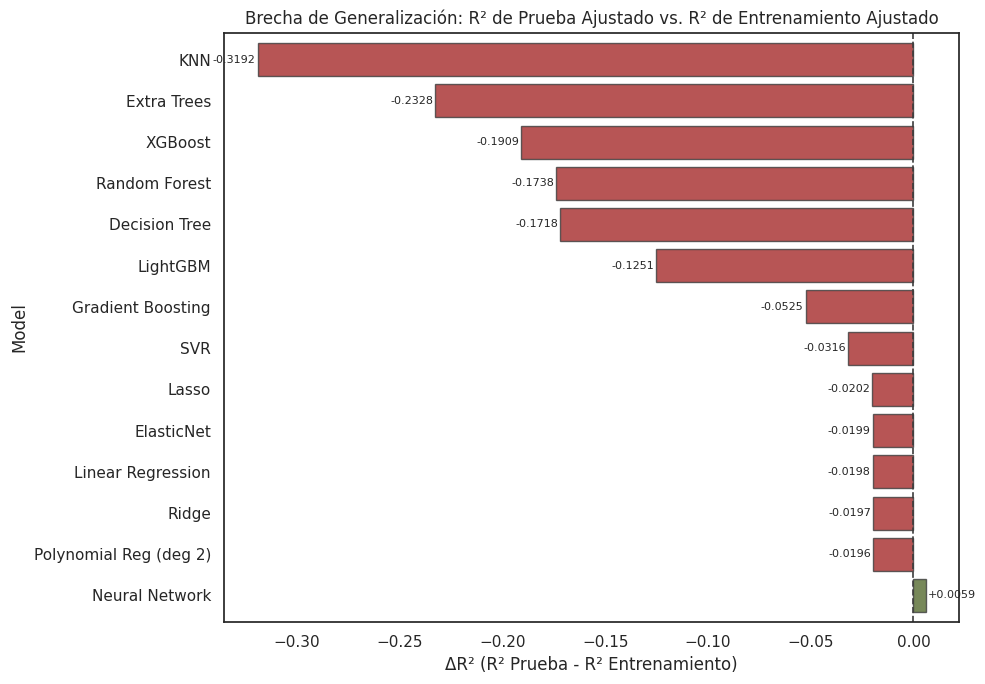


=== VERIFICACIÓN ===
--------------------------------------------------------------------------------------------------------------
Rango de Delta (R²)  | Interpretación                 | Estado          | Acción
--------------------------------------------------------------------------------------------------------------
+0.05 a -0.05        | Robusto y Estable              | Óptimo          | Aprobar. Generaliza perfectamente.
-0.05 a -0.10        | Sobreajuste Moderado           | Advertencia     | Revisar. Considerar regularización leve.
< -0.10              | Sobreajuste Severo             | Crítico         | Rechazar. Memoriza ruido de entrenamiento.
+0.05 a +0.10        | Alta Varianza / Partición Afortunada | Precaución      | Validar. Ejecutar más validación cruzada.
> +0.10              | Inestabilidad de Datos         | Alerta          | Investigar. Verificar posible fuga de datos (data leakage).


In [112]:
# Calcular la brecha de generalización entre R² de Prueba y Entrenamiento
before = tuning_df.set_index('Model')['Train R²']
after  = tuning_df.set_index('Model')['Test R²']
delta  = (after - before).sort_values(ascending=False) # Mantiene tu orden original

# Graficar la brecha de generalización
fig, ax = plt.subplots(figsize=(10, 7)) # 1. Cambiado a (10, 7) para dar más espacio vertical
colors  = ['#556B2F' if v >= 0 else '#A52A2A' for v in delta]

# SE AGREGA width=0.8 (así controla Pandas el grosor en barh)
delta.plot(kind='barh', ax=ax, color=colors, edgecolor='#3D3D3D', alpha=0.8, width=0.8)


# Estilo del gráfico y anotaciones
ax.axvline(0, color='#3D3D3D', lw=1.2, linestyle='--')
ax.set(title='Brecha de Generalización: R² de Prueba Ajustado vs. R² de Entrenamiento Ajustado',
       xlabel='ΔR² (R² Prueba - R² Entrenamiento)')

# Tus etiquetas siguen funcionando perfectamente en su misma posición
for i, v in enumerate(delta):
    ax.text(v + 0.001 if v >= 0 else v - 0.001, i,
            f'{v:+.4f}', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
plt.tight_layout()
plt.show()

print('\n=== VERIFICACIÓN ===')
print("-" * 110)
print(f"{'Rango de Delta (R²)':<20} | {'Interpretación':<30} | {'Estado':<15} | {'Acción'}")
print("-" * 110)

performance_metrics = [
    ("+0.05 a -0.05", "Robusto y Estable", "Óptimo", "Aprobar. Generaliza perfectamente."),
    ("-0.05 a -0.10", "Sobreajuste Moderado", "Advertencia", "Revisar. Considerar regularización leve."),
    ("< -0.10", "Sobreajuste Severo", "Crítico", "Rechazar. Memoriza ruido de entrenamiento."),
    ("+0.05 a +0.10", "Alta Varianza / Partición Afortunada", "Precaución", "Validar. Ejecutar más validación cruzada."),
    ("> +0.10", "Inestabilidad de Datos", "Alerta", "Investigar. Verificar posible fuga de datos (data leakage).")
]

for rng, interp, status, action in performance_metrics:
    print(f"{rng:<20} | {interp:<30} | {status:<15} | {action}")

In [128]:
# Encuentra la fila con el error más alto
yp = BEST_MODELS['LightGBM'].predict(X_test)
diff = np.abs(y_test - yp)
idx_max_error = diff.idxmax()
print(df.loc[idx_max_error])

house_age         20.0
households        15.0
income          2.4444
population        31.0
latitude         37.88
longitude      -122.22
rooms             95.0
bedrooms          13.0
ocean_dist    near bay
price         475000.0
Name: 1350, dtype: object


#### Ganancia Neta por Optimización de Hiperparámetros: R² Ajustado - R² Base (Por Defecto)

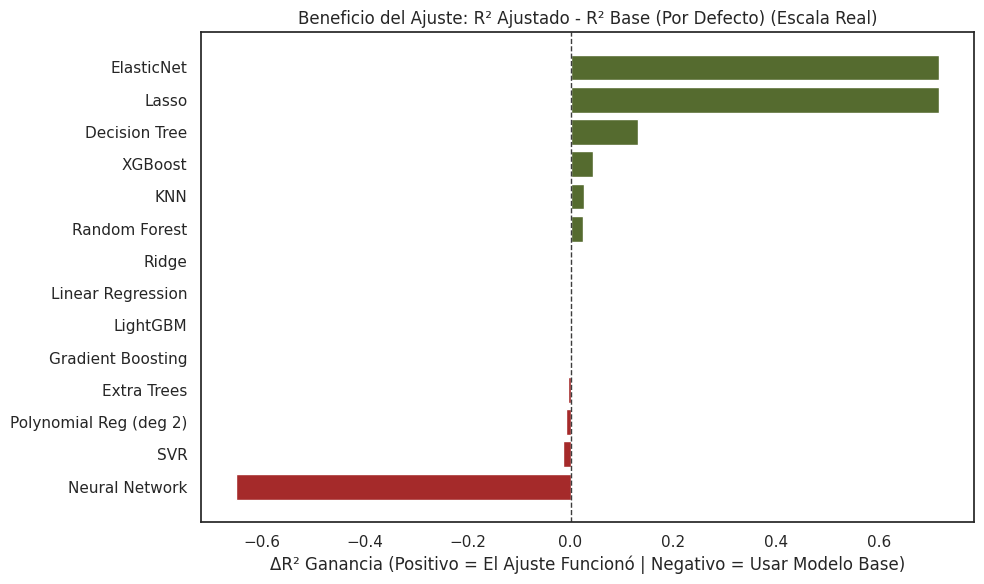


### VERIFICACIÓN ###
----------------------------------------------------------------------------------------------------------------------------------
Mejora (ΔR²)         | Interpretación                                | Estado          | Acción
----------------------------------------------------------------------------------------------------------------------------------
> +0.10              | Ganancia Masiva (Alto Impacto)                | Éxito+          | Excelente. Verificar estabilidad / sin fuga de datos.
+0.005 a +0.10       | Mejora Saludable                              | Éxito           | Mantener versión ajustada. Buena optimización.
-0.005 a +0.005      | Cambio Insignificante (Límite Alcanzado)      | Neutral         | Usar modelo base o ajustado. Mejor la simplicidad.
-0.005 a -0.05       | Ligera Caída de Rendimiento                   | Advertencia     | Revisar. El ajuste sobreajustó los pliegues de validación cruzada.
< -0.05              | Pérdida Significativa 

In [114]:
#  Definir un límite superior seguro basado en el máximo real de test
max_log_val = y_test.max() + 2.0

tuning_impact = []

for name, model in MODELS.items():
    # Evaluar modelo base (hiperparámetros por defecto)
    base_model = clone(model)
    base_model.fit(X_train, y_train)

    # Corregido: Comparación directa en la escala real actual de tus variables
    r2_base = r2_score(y_test, base_model.predict(X_test))

    # Obtener rendimiento del modelo ajustado a partir de resultados previos
    r2_tuned = tuning_df.loc[tuning_df['Model'] == name, 'Test R²'].values[0]

    tuning_impact.append({
        'Model': name,
        'Base R2': r2_base,
        'Tuned R2': r2_tuned,
        'Improvement': r2_tuned - r2_base
    })

  # Finalizar DataFrame de impacto
impact_df = pd.DataFrame(tuning_impact).sort_values('Improvement', ascending=True)

plt.figure(figsize=(10, 6))
colors = ['#556B2F' if v >= 0 else '#A52A2A' for v in impact_df['Improvement']]
plt.barh(impact_df['Model'], impact_df['Improvement'], color=colors)
plt.axvline(0, color='#3D3D3D', linestyle='--', lw=1)
plt.title('Beneficio del Ajuste: R² Ajustado - R² Base (Por Defecto) (Escala Real)')
plt.xlabel('ΔR² Ganancia (Positivo = El Ajuste Funcionó | Negativo = Usar Modelo Base)')
plt.tight_layout()
plt.show()

print('\n### VERIFICACIÓN ###')
print("-" * 130)
print(f"{'Mejora (ΔR²)':<20} | {'Interpretación':<45} | {'Estado':<15} | {'Acción'}")
print("-" * 130)

tuning_metrics = [
    ("> +0.10", "Ganancia Masiva (Alto Impacto)", "Éxito+", "Excelente. Verificar estabilidad / sin fuga de datos."),
    ("+0.005 a +0.10", "Mejora Saludable", "Éxito", "Mantener versión ajustada. Buena optimización."),
    ("-0.005 a +0.005", "Cambio Insignificante (Límite Alcanzado)", "Neutral", "Usar modelo base o ajustado. Mejor la simplicidad."),
    ("-0.005 a -0.05", "Ligera Caída de Rendimiento", "Advertencia", "Revisar. El ajuste sobreajustó los pliegues de validación cruzada."),
    ("< -0.05", "Pérdida Significativa (Fallo de Optimización)", "Crítico", "Rechazar. Revertir al modelo base inmediatamente.")
]

for rng, interp, status, action in tuning_metrics:

    print(f"{rng:<20} | {interp:<45} | {status:<15} | {action}")

print("-" * 130)

### Pruebas de Robustez (Validación Final)

#### Validación Cruzada K-Fold: Estabilidad Interna por División del Conjunto y Uso de Hiperparámetros Óptimos

In [ ]:
# Mapear resultados existentes para comparación final
results_base_dict = benchmark_df.set_index('Model')['Test R² (default)'].to_dict()
results_tuned_dict = tuning_df.set_index('Model')['Test R²'].to_dict()

# Configurar estrategia de validación cruzada y contenedores
from sklearn.model_selection import cross_validate
cv_rows = []

# Ejecutar bucle de validación final usando modelos optimizados
for name, model in BEST_MODELS.items():
    # Evaluación robusta multi-métrica en un solo paso
    cv_scores = cross_validate(
        model, X_train, y_train, cv=kf,
        scoring={'r2': 'r2', 'mse': 'neg_mean_squared_error'},
        n_jobs=-1
    )

    r2_test_base  = results_base_dict.get(name, 0)
    r2_test_tuned = results_tuned_dict.get(name, 0)

    cv_rows.append({
        'Model': name,
        'Base Test R²': round(r2_test_base, 4),
        'Tuned Test R²': round(r2_test_tuned, 4),
        'Tuned CV R² (Mean)': round(cv_scores['test_r2'].mean(), 4),
        'Tuned CV R² (Std)': round(cv_scores['test_r2'].std(), 4),
        'Tuned CV RMSE (Mean)': round(np.mean(np.sqrt(-cv_scores['test_mse'])), 4)
    })

# Generar reporte final
cv_results_df = pd.DataFrame(cv_rows).sort_values('Tuned Test R²', ascending=False).reset_index(drop=True)
display(cv_results_df.style.background_gradient(cmap='RdYlGn', subset=['Tuned Test R²', 'Tuned CV R² (Mean)']))

# Verificación rápida
print('\n### VERIFICACIÓN ###')
print('¿El modelo siempre se desempeña de forma similar o depende de la partición?')
print('Media de CV R²: mayor = mejor rendimiento promedio | Desv. est. de CV R²: menor = más estable\nRMSE de CV: menor = mejor error\nCRITERIO FINAL: 1) Media de CV R² ↑ 2) RMSE de CV ↓ 3) Desv. est. de CV R² ↓ (consistencia)')

,Model,Base Test R²,Tuned Test R²,Tuned CV R² (Mean),Tuned CV R² (Std),Tuned CV RMSE (Mean)
0,XGBoost,0.721300,0.764200,0.792100,0.027700,54147.675100
1,LightGBM,0.750800,0.750500,0.776200,0.022400,56160.190700
2,Random Forest,0.726400,0.749800,0.755900,0.031100,58668.893800
3,Gradient Boosting,0.738200,0.737500,0.743800,0.025900,60081.671600
4,Extra Trees,0.733600,0.729100,0.761500,0.026000,57977.208000
5,Polynomial Reg (deg 2),0.712400,0.703600,0.696900,0.032200,65383.839100
6,SVR,0.711400,0.696300,0.712400,0.029600,63629.757800
7,KNN,0.654200,0.680800,0.710800,0.017800,63818.129300
8,Linear Regression,0.662800,0.662800,0.678800,0.033700,67277.093000
9,Ridge,0.662200,0.662800,0.678800,0.033700,67278.897500



### VERIFICACIÓN ###
¿El modelo siempre se desempeña de forma similar o depende de la partición?
Media de CV R²: mayor = mejor rendimiento promedio | Desv. est. de CV R²: menor = más estable
RMSE de CV: menor = mejor error
CRITERIO FINAL: 1) Media de CV R² ↑ 2) RMSE de CV ↓ 3) Desv. est. de CV R² ↓ (consistencia)


#### Prueba de Estabilidad con Múltiples Semillas: Estabilidad Externa con Diferentes Semillas y Uso de Hiperparámetros Óptimos

In [ ]:
# Bucle de prueba de estabilidad con múltiples semillas (versión corregida y optimizada)
SEEDS = [7, 19, 58, 73, 101, 256, 389, 512, 777, 888, 1024, 1337, 2024, 4096, 8191]
stability = []

# Ejecutar prueba de estabilidad con múltiples semillas
for name, model in BEST_MODELS.items():
    r2s = []

    for s in SEEDS:
        # 1. CORRECCIÓN: Uso correcto de 'random_state=s' para variar los splits
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=s)

        # NOTA: No llamamos a preprocess(). El TransformedTargetRegressor del pipeline
        # se encarga de aplicar el log1p internamente al entrenar.
        model_clone = clone(model)
        model_clone.fit(Xtr, ytr)

        # 2. CORRECCIÓN: El método .predict() del pipeline ya devuelve los datos en la
        # escala original de dólares (aplica expm1 automáticamente). Se compara directo con 'yte'.
        r2 = r2_score(yte, model_clone.predict(Xte))
        r2s.append(r2)

    # Convertimos a array de numpy para evitar listas redundantes de semillas y optimizar la indexación
    r2s_np = np.array(r2s)
    idx_max = np.argmax(r2s_np)
    idx_min = np.argmin(r2s_np)  # 3. CORRECCIÓN: np.armin -> np.argmin

    stability.append({
        'Model'      : name,
        'R² mean'    : round(r2s_np.mean(), 4),
        'R² std'     : round(r2s_np.std(), 4),
        'R² min'     : round(r2s_np[idx_min], 4),
        'Seed min'   : SEEDS[idx_min],
        'R² max'     : round(r2s_np[idx_max], 4),
        'Seed max'   : SEEDS[idx_max],
        'Range'      : round(r2s_np[idx_max] - r2s_np[idx_min], 4),
    })

# Visualización de resultados
stability_df = (pd.DataFrame(stability).sort_values('R² mean', ascending=False).reset_index(drop=True))
display(stability_df.style.background_gradient(cmap='RdYlGn', subset=['R² mean', 'R² std', 'Range']))

# Verificación rápida
print('\n=== VERIFICACIÓN ===')
print('¿El modelo es bueno o solo tuvo "suerte" con la semilla (SEED)?')
print('Media de R²: mayor = mejor rendimiento promedio | Desv. est. de R²: menor (menor a 0.05 → modelo estable) = más estable (menor sensibilidad a la partición → sin sobreajuste potencial).\nR² mín/máx: rango de peor/mejor caso | Rango: menor = más robusto (mayor a 0.15 → sobreajuste severo)\nCRITERIO FINAL: 1) Media de R² ↑ 2) Desv. est. de R² ↓ 3) Rango ↓')

,Model,R² mean,R² std,R² min,Seed min,R² max,Seed max,Range
0,XGBoost,0.779100,0.014900,0.753200,1337,0.810200,4096,0.057000
1,LightGBM,0.764900,0.016500,0.737300,1337,0.803500,4096,0.066300
2,Random Forest,0.747500,0.016400,0.714300,2024,0.783900,4096,0.069600
3,Extra Trees,0.744200,0.017300,0.709800,2024,0.781200,4096,0.071500
4,Gradient Boosting,0.732000,0.014100,0.701500,73,0.767800,4096,0.066300
5,SVR,0.703800,0.015700,0.677600,73,0.735200,4096,0.057700
6,Polynomial Reg (deg 2),0.690300,0.018800,0.655300,73,0.728100,4096,0.072700
7,KNN,0.684800,0.018100,0.654200,73,0.718500,4096,0.064300
8,Linear Regression,0.670800,0.018800,0.646100,2024,0.709600,8191,0.063500
9,Ridge,0.670800,0.018800,0.646100,2024,0.709600,8191,0.063600



=== VERIFICACIÓN ===
¿El modelo es bueno o solo tuvo "suerte" con la semilla (SEED)?
Media de R²: mayor = mejor rendimiento promedio | Desv. est. de R²: menor (menor a 0.05 → modelo estable) = más estable (menor sensibilidad a la partición → sin sobreajuste potencial).
R² mín/máx: rango de peor/mejor caso | Rango: menor = más robusto (mayor a 0.15 → sobreajuste severo)
CRITERIO FINAL: 1) Media de R² ↑ 2) Desv. est. de R² ↓ 3) Rango ↓


## Evaluación del Modelo

In [117]:
# Definir visualizador de diagnóstico de residuos
def plot_residuals_rf(model, X_train, y_train, X_test, y_test):

    # Evitar problemas de renderizado en Colab
    plt.close('all')

    # Asegurar que el modelo esté entrenado y generar predicciones de prueba
    model.fit(X_train, y_train)
    yp  = model.predict(X_test)
    res = y_test - yp

    # Configurar cuadrícula de diagnóstico de 2x3
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Diagnóstico de Residuos — Rendimiento del Modelo (TEST)', fontweight='bold', fontsize=16)

    # Gráfico 1: Real vs. Predicho (Ideal: línea de 45 grados)
    axes[0, 0].scatter(y_test, yp, alpha=0.4, color='tab:blue')
    lims = [min(y_test.min(), yp.min()), max(y_test.max(), yp.max())]
    axes[0, 0].plot(lims, lims, 'k--')
    axes[0, 0].set_title('Real vs. Predicho')
    axes[0, 0].set_xlabel('Real')
    axes[0, 0].set_ylabel('Predicho')

    # Gráfico 2: Distribución de residuos (Ideal: distribución normal centrada en 0)
    sns.histplot(res, kde=True, ax=axes[0, 1], color='tab:blue')
    axes[0, 1].axvline(0, linestyle='--', color='black')
    axes[0, 1].set_title('Distribución de Residuos')

    # Gráfico 3: Gráfico Q-Q (Ideal: puntos siguiendo la diagonal)
    sm.qqplot(res, line='q', ax=axes[0, 2], fit=True)
    axes[0, 2].set_title('Gráfico Q-Q')

    # Gráfico 4: Residuos vs. Índice (detectar patrones secuenciales)
    axes[1, 0].scatter(range(len(res)), res, alpha=0.4, edgecolors='black')
    axes[1, 0].axhline(y=0, linestyle='--', color='red', lw=2)
    axes[1, 0].set_title('Residuos vs. Índice')
    axes[1, 0].set_xlabel('Índice')
    axes[1, 0].set_ylabel('Residuo')

    # Gráfico 5: Residuos vs. Predicho (detectar heterocedasticidad)
    axes[1, 1].scatter(yp, res, alpha=0.4, color='tab:blue')
    axes[1, 1].axhline(y=0, linestyle='--', color='red', lw=2)
    axes[1, 1].set_title('Residuos vs. Predicho')
    axes[1, 1].set_xlabel('Predicho')
    axes[1, 1].set_ylabel('Residuo')

    # Limpiar eje no utilizado
    fig.delaxes(axes[1, 2])
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

### Residuos

### Mejor Modelo Seleccionado

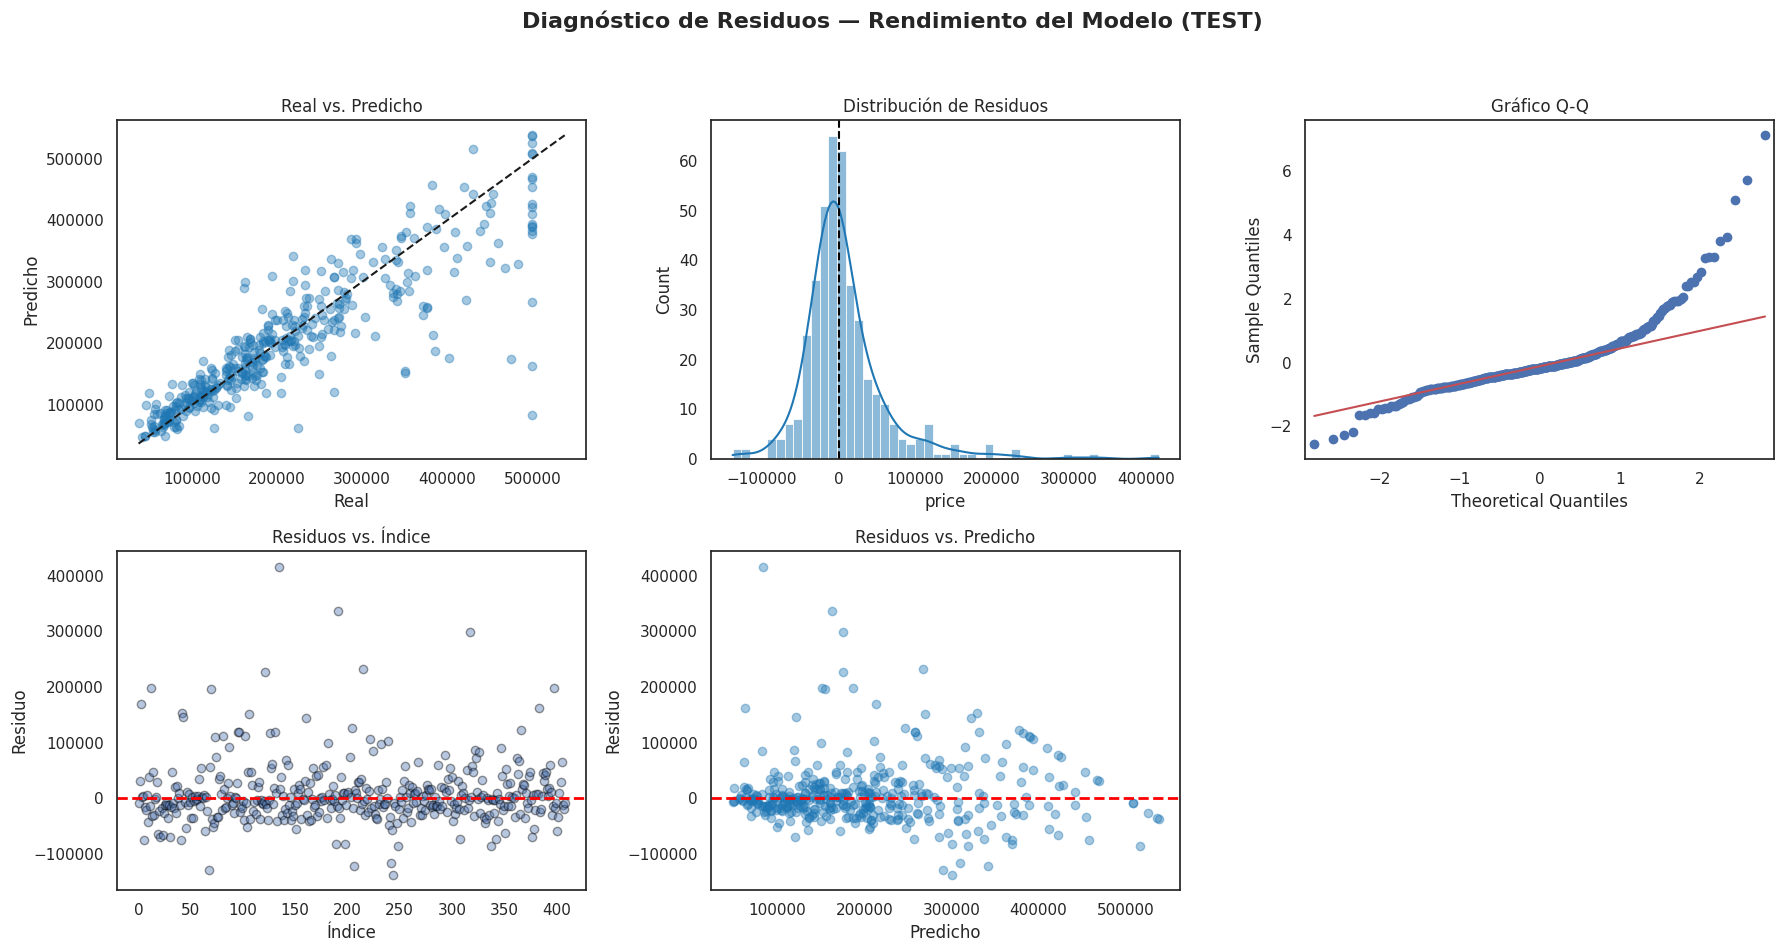


=== REAL VS. PREDICHO ===
IDEAL       : Puntos sobre la diagonal.
POR ENCIMA  : Subestimando (Predicho < Real).
POR DEBAJO  : Sobrestimando (Predicho > Real).

=== DISTRIBUCIÓN DE RESIDUOS ===
IDEAL          : Curva acampanada centrada en 0.
COLAS          : Valores atípicos con alto error detectados.
SESGO DERECHO  : Subestimación (el modelo predice por debajo de los precios reales).
SESGO IZQUIERDO: Sobrestimación (el modelo predice por encima de los precios reales).

=== GRÁFICO Q-Q ===
IDEAL  : Los puntos siguen la línea roja.
CURVAS : Errores no normales (el modelo está sesgado).

=== RESIDUOS VS. ÍNDICE ===
IDEAL      : Nube aleatoria alrededor de la línea 0.
TENDENCIAS : Los errores dependen del orden de las filas (posible fuga de datos o efecto temporal).

=== RESIDUOS VS. PREDICHO ===
IDEAL       : Nube aleatoria, sin patrón claro.
EMBUDO      : El error crece con el precio (considerar transformación logarítmica).
PATRÓN EN U : Al modelo le falta capturar una relación no line

In [ ]:
# Gráficos
# Opción 1: Automático (el #1 del ranking)
best_model_name = tuning_df.iloc[0]['Model']

# Opción 2: Manual (descomenta la siguiente línea cuando quieras elegirlo tú)
# best_model_name = 'Random Forest'

rf_model = BEST_MODELS[best_model_name]
plot_residuals_rf(rf_model, X_train, y_train, X_test, y_test)

# Verificación rápida
# Real vs. Predicho
print('\n=== REAL VS. PREDICHO ===')
print('IDEAL       : Puntos sobre la diagonal.')
print('POR ENCIMA  : Subestimando (Predicho < Real).')
print('POR DEBAJO  : Sobrestimando (Predicho > Real).')

# Distribución de residuos
print('\n=== DISTRIBUCIÓN DE RESIDUOS ===')
print('IDEAL          : Curva acampanada centrada en 0.')
print('COLAS          : Valores atípicos con alto error detectados.')
print('SESGO DERECHO  : Subestimación (el modelo predice por debajo de los precios reales).')
print('SESGO IZQUIERDO: Sobrestimación (el modelo predice por encima de los precios reales).')

# Gráfico Q-Q
print('\n=== GRÁFICO Q-Q ===')
print('IDEAL  : Los puntos siguen la línea roja.')
print('CURVAS : Errores no normales (el modelo está sesgado).')

# Residuos vs. Índice
print('\n=== RESIDUOS VS. ÍNDICE ===')
print('IDEAL      : Nube aleatoria alrededor de la línea 0.')
print('TENDENCIAS : Los errores dependen del orden de las filas (posible fuga de datos o efecto temporal).')

# Residuos vs. Predicho
print('\n=== RESIDUOS VS. PREDICHO ===')
print('IDEAL       : Nube aleatoria, sin patrón claro.')
print('EMBUDO      : El error crece con el precio (considerar transformación logarítmica).')
print('PATRÓN EN U : Al modelo le falta capturar una relación no lineal.')

| Componente del Código | Algoritmos Compatibles | Algoritmos Incompatibles (o que Requieren Cambios) |
|---|---|---|
| **Gráficos de Residuos y Error Absoluto** | Todos (Lineales, KNN, SVR, Árboles, Ensambles, TabPFN) | Ninguno (solo requieren que el modelo tenga el método `predict()`) |

### Análisis de Heterocedasticidad por Variable

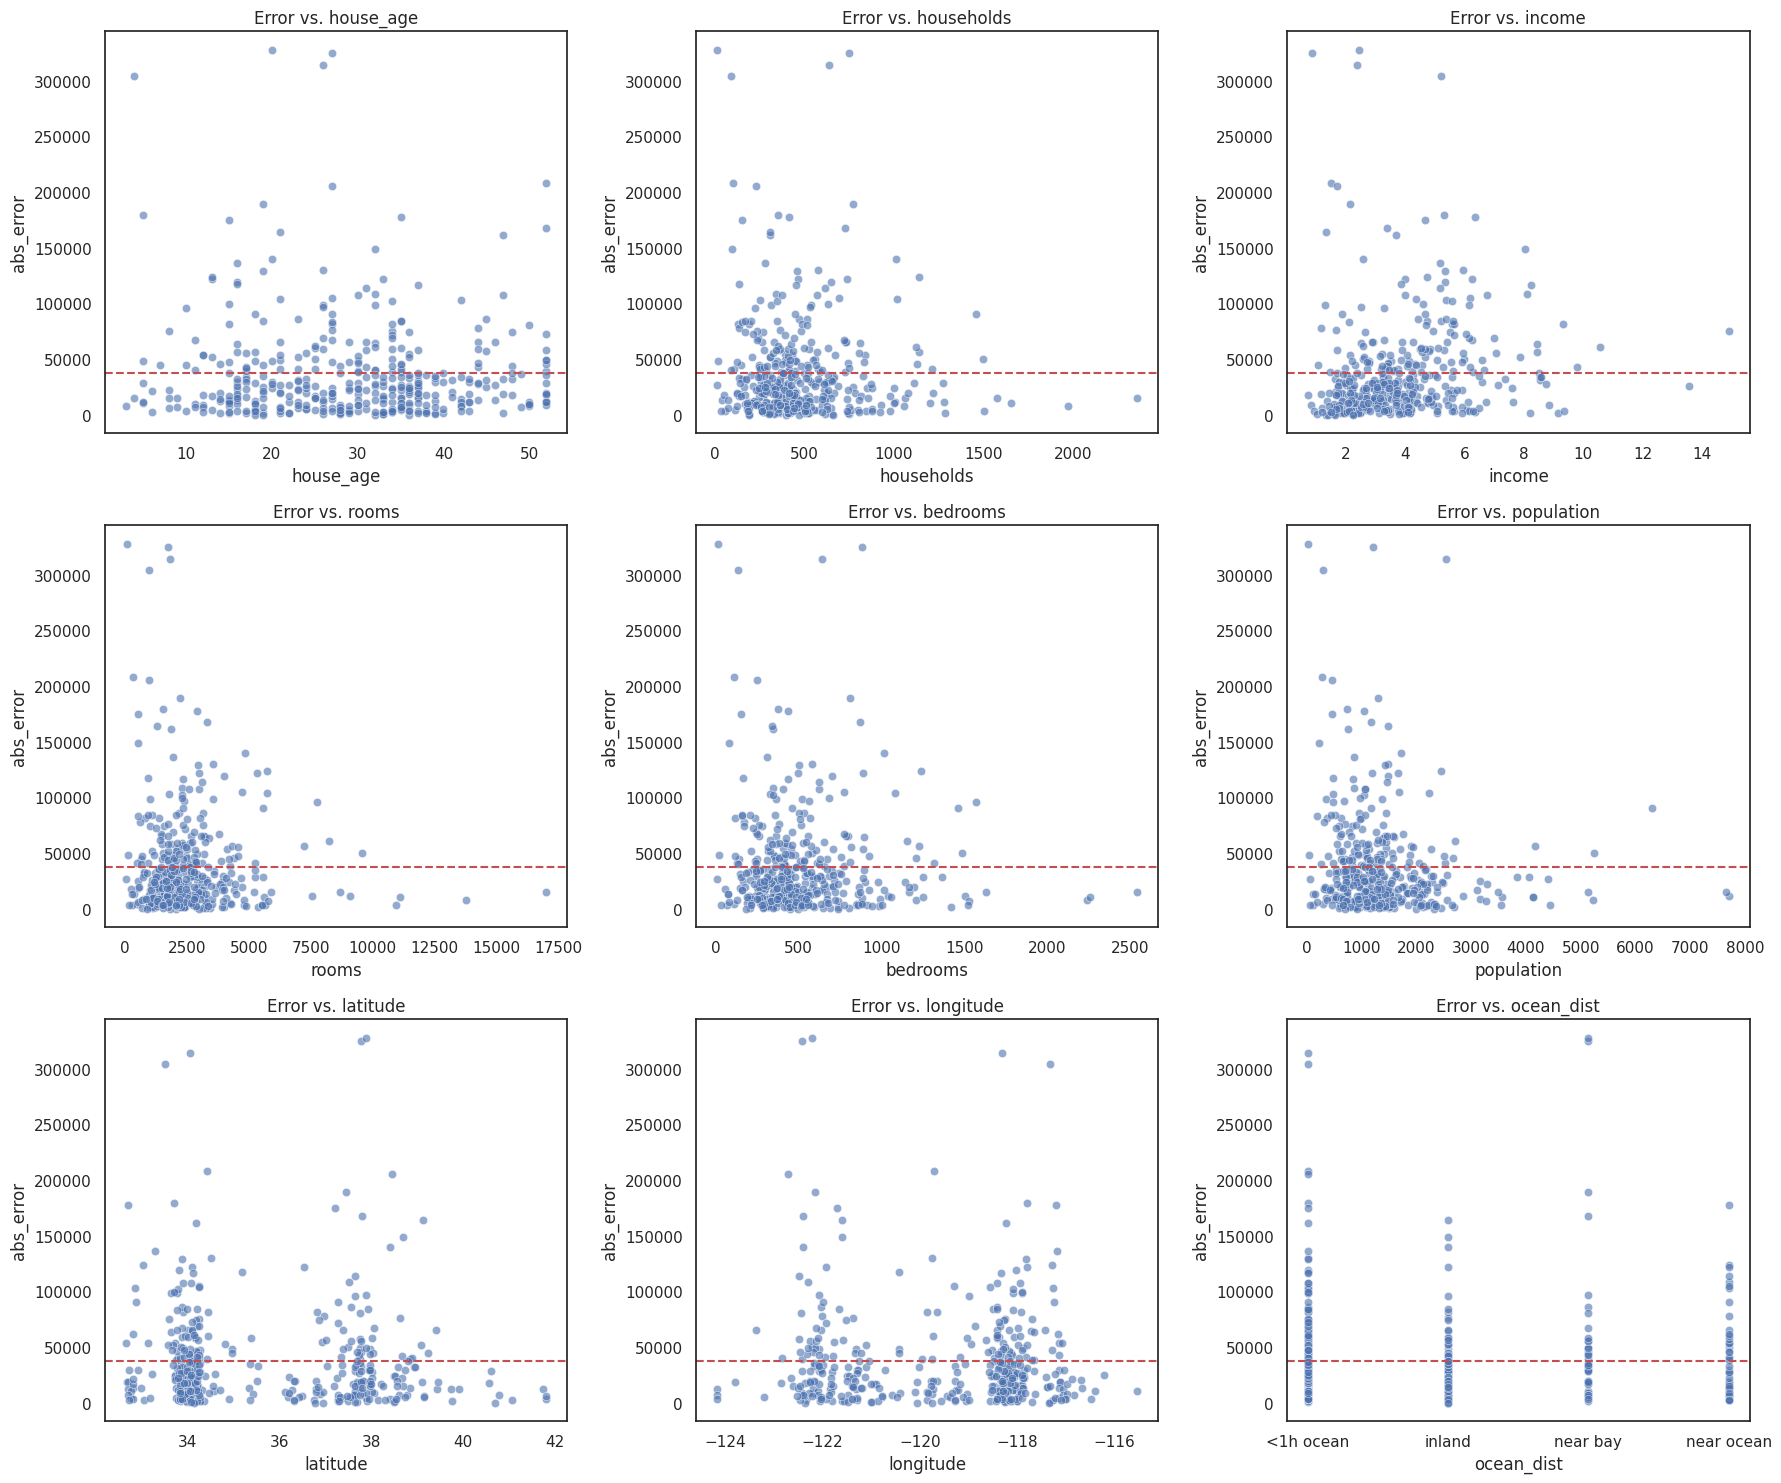

In [ ]:
# Calcular error absoluto para detección de sesgo
yp = rf_model.predict(X_test)
abs_error = np.abs(y_test - yp)

# Crear DataFrame de diagnóstico
df_err = X_test.copy()
df_err['abs_error'] = abs_error

# Configurar cuadrícula dinámica para subgráficos
cols = X_test.columns
n_cols = 3
n_rows = (len(cols) + n_cols - 1) // n_cols

# Graficar error vs. características para detectar heterocedasticidad
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.scatterplot(x=df_err[col], y=df_err['abs_error'], ax=axes[i], alpha=0.6)
    axes[i].set_title(f'Error vs. {col}')
    axes[i].axhline(y=df_err['abs_error'].mean(), color='r', linestyle='--', label='Error medio')

# Limpiar subgráficos vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### SHAP
Solo funcionan para modelos basados en árboles (Random Forest, Extra Trees, Decision Tree, Gradient Boosting, XGBoost y LightGBM):

#### Base

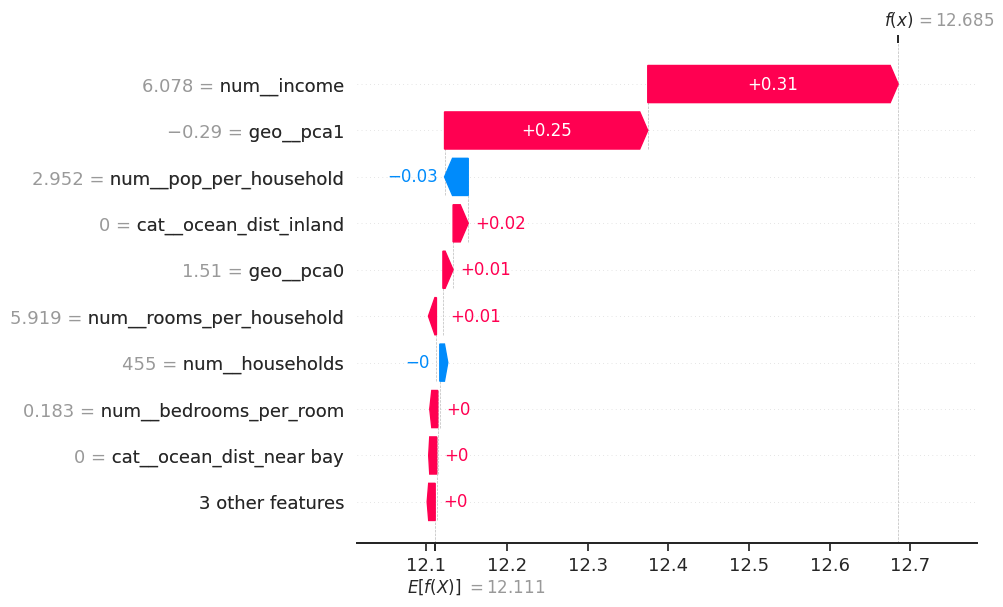

Precio base promedio : $181,871
Precio predicho      : $322,855


In [ ]:
import shap

# Configuración de SHAP
current_model      = rf_model.regressor_.named_steps['model']
X_test_transformed = rf_model.regressor_.named_steps['prep'].transform(X_test)
feature_names      = rf_model.regressor_.named_steps['prep'].get_feature_names_out()

explainer   = shap.TreeExplainer(current_model) # <-- para árboles, para otro algoritmo se usa otro explicador de SHAP
shap_values = explainer.shap_values(X_test_transformed)

base_val = explainer.expected_value
if isinstance(base_val, (np.ndarray, list)):
    base_val = base_val[0]

# Mostrar waterfall de la primera observación
exp = shap.Explanation(
    values        = shap_values[0],
    base_values   = base_val,
    data          = X_test_transformed[0],
    feature_names = feature_names
)

shap.plots.waterfall(exp)

# Precio real
print(f"Precio base promedio : ${np.expm1(base_val):,.0f}")
print(f"Precio predicho      : ${np.expm1(base_val + shap_values[0].sum()):,.0f}")

In [ ]:
# Comprueba que rf_model existe
print(type(rf_model))

# Comprueba que tiene regressor_
print(type(rf_model.regressor_))

# Comprueba los pasos del pipeline
print(rf_model.regressor_.named_steps.keys())

<class 'sklearn.compose._target.TransformedTargetRegressor'>
<class 'sklearn.pipeline.Pipeline'>
dict_keys(['prep', 'model'])


#### Resumen

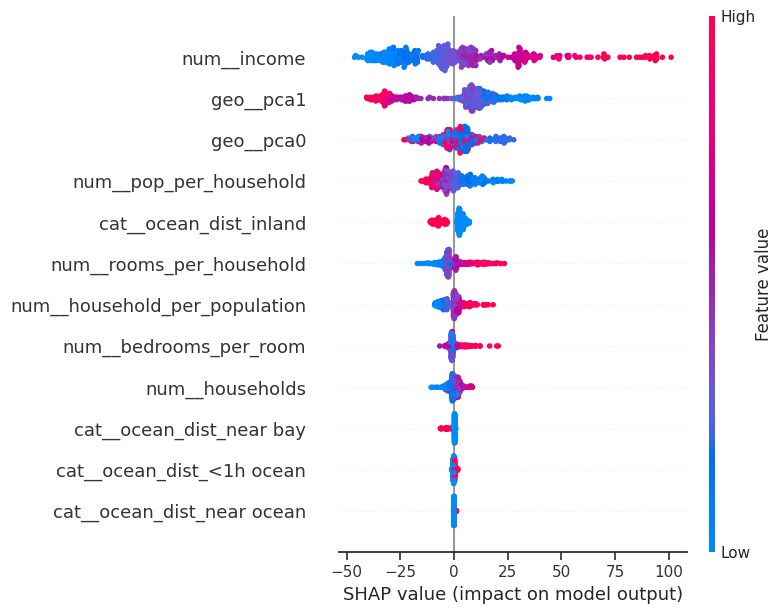


IMPORTANCIA (Arriba = mayor influencia global)
→ Eje X (Valor SHAP %)
  Los valores representan el impacto porcentual sobre la predicción.
  + a la derecha = incrementa la predicción en un X%
  - a la izquierda = reduce la predicción en un X%

COLOR
🔴 Rojo  = Valor alto de la variable
🔵 Azul  = Valor bajo de la variable



In [ ]:
# Resumen
shap_values_percent = (np.exp(shap_values) - 1) * 100
shap.summary_plot(shap_values_percent, X_test_transformed, feature_names=feature_names)

# Verificación rápida
print('''
IMPORTANCIA (Arriba = mayor influencia global)
→ Eje X (Valor SHAP %)
  Los valores representan el impacto porcentual sobre la predicción.
  + a la derecha = incrementa la predicción en un X%
  - a la izquierda = reduce la predicción en un X%

COLOR
🔴 Rojo  = Valor alto de la variable
🔵 Azul  = Valor bajo de la variable
''')

#### Cascada (Individual)

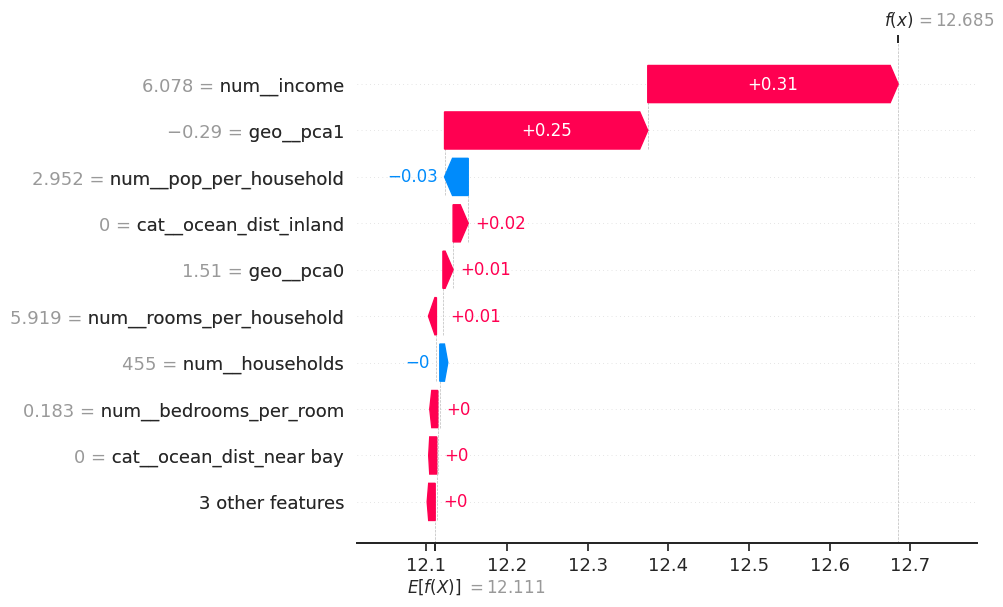


=== VERIFICACIÓN ===
IMPORTANCIA : ¿En la parte superior? → Mayor impacto en el modelo.
BEESWARM (General):
   - 🔴 Derecha    : Valor ALTO de la característica AUMENTA la predicción.
   - 🔵 Derecha    : Valor BAJO de la característica AUMENTA la predicción.
WATERFALL (Caso i):
   - 🔴 Bloque     : Suma puntos (+).
   - 🔵 Bloque     : Resta puntos (-).
   - Trayectoria   : Desde la base E[f(x)] → hasta el valor final f(x).


In [ ]:
# Cascada (Individual): 1.ª fila de X_test
i = 0

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[i],
        base_values=explainer.expected_value,
        data=X_test_transformed[i],          # <-- transformado, no X_test.iloc[i]
        feature_names=feature_names
    )
)

# Verificación rápida
print('\n=== VERIFICACIÓN ===')
print('IMPORTANCIA : ¿En la parte superior? → Mayor impacto en el modelo.')
print('BEESWARM (General):')
print('   - 🔴 Derecha    : Valor ALTO de la característica AUMENTA la predicción.')
print('   - 🔵 Derecha    : Valor BAJO de la característica AUMENTA la predicción.')
print('WATERFALL (Caso i):')
print('   - 🔴 Bloque     : Suma puntos (+).')
print('   - 🔵 Bloque     : Resta puntos (-).')
print('   - Trayectoria   : Desde la base E[f(x)] → hasta el valor final f(x).')

#### Gráfico de Dependencia

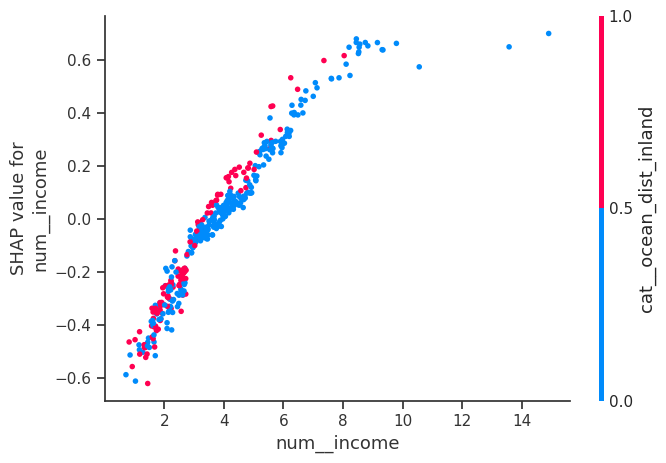


=== VERIFICACIÓN ===
CRUCE POR CERO: Punto donde Y=0 | Por encima de 0 = El precio aumenta (+) | Por debajo de 0 = El precio disminuye (-)


In [ ]:
# Identificar la característica más influyente según valores SHAP
most_important_idx = np.abs(shap_values).mean(0).argmax()
most_important     = feature_names[most_important_idx]

# Generar gráfico de dependencia SHAP
shap.dependence_plot(
    most_important,
    shap_values,
    X_test_transformed,          #
    feature_names=feature_names  #
)

# Verificación rápida
print('\n=== VERIFICACIÓN ===')
print('CRUCE POR CERO: Punto donde Y=0 | Por encima de 0 = El precio aumenta (+) | Por debajo de 0 = El precio disminuye (-)')

## Conclusiones

In [ ]:
# Combinar todas las métricas en un solo DataFrame
summary_report = (
    tuning_df.drop(columns=['Best Params'])
    .merge(cv_results_df, on='Model', how='left')
    .merge(stability_df, on='Model', how='left')
)

# Reordenar columnas para mejor legibilidad
cols_order = [
    'Model', 'Test R²', 'CV R² mean', 'R² mean', 'R² std',
    'Test RMSE', 'CV RMSE', 'Test MAE', 'Gap'
]

# Mantener solo columnas existentes para evitar errores
existing_cols = [c for c in cols_order if c in summary_report.columns]
summary_report = summary_report[
    existing_cols + [c for c in summary_report.columns if c not in existing_cols]
]

# Guardar y descargar reporte
file_name = '/content/drive/MyDrive/Colab Notebooks/Bd/real_estate_model_comparison.csv'
summary_report.to_csv(file_name, index=False)
print(f'✅ Reporte guardado como: {file_name}')

try:
    files.download(file_name)
except Exception as e:
    print(f'Descarga no disponible: {e}')

# Mostrar tabla con estilo
display(
    summary_report.style
    .background_gradient(cmap='RdYlGn', subset=['Test R²', 'R² mean', 'R² std']))

✅ Reporte guardado como: /content/drive/MyDrive/Colab Notebooks/Bd/real_estate_model_comparison.csv
Descarga no disponible: name 'files' is not defined


,Model,Test R²,R² mean,R² std,Test RMSE,Test MAE,Gap,Test R² (default),CV R² (default),CV R²,Train R²,Test MAPE,Test MSLE,Test MaxErr,Mean Error,Δ R²,Base Test R²,Tuned Test R²,Tuned CV R² (Mean),Tuned CV R² (Std),Tuned CV RMSE (Mean),R² min,Seed min,R² max,Seed max,Range
0,XGBoost,0.764200,0.779100,0.014900,57923.164000,35179.592100,0.190900,0.721300,0.782100,0.792100,0.955100,17.040000,0.067300,416698.726600,46551.378000,0.042900,0.721300,0.764200,0.792100,0.027700,54147.675100,0.753200,1337,0.810200,4096,0.057000
1,LightGBM,0.750500,0.764900,0.016500,59578.645400,37700.533600,0.125000,0.750800,0.793200,0.776200,0.875600,18.780000,0.071800,327813.437900,48639.589500,-0.000300,0.750800,0.750500,0.776200,0.022400,56160.190700,0.737300,1337,0.803500,4096,0.066300
2,Random Forest,0.749800,0.747500,0.016400,59667.610400,38689.593200,0.173900,0.726400,0.766400,0.755900,0.923600,19.690000,0.072900,354329.545800,49178.601800,0.023400,0.726400,0.749800,0.755900,0.031100,58668.893800,0.714300,2024,0.783900,4096,0.069600
3,Gradient Boosting,0.737500,0.732000,0.014100,61119.258200,39542.268100,0.052500,0.738200,0.767600,0.743800,0.790000,19.460000,0.071900,348452.612500,50330.763100,-0.000700,0.738200,0.737500,0.743800,0.025900,60081.671600,0.701500,73,0.767800,4096,0.066300
4,Extra Trees,0.729100,0.744200,0.017300,62082.781000,38758.692700,0.232800,0.733600,0.768300,0.761500,0.961900,19.370000,0.079900,426320.661100,50420.736900,-0.004500,0.733600,0.729100,0.761500,0.026000,57977.208000,0.709800,2024,0.781200,4096,0.071500
5,Polynomial Reg (deg 2),0.703600,0.690300,0.018800,64939.459500,43044.661900,0.019600,0.712400,0.692300,0.696900,0.723200,22.560000,0.091000,329945.512500,53992.060700,-0.008800,0.712400,0.703600,0.696900,0.032200,65383.839100,0.655300,73,0.728100,4096,0.072700
6,SVR,0.696300,0.703800,0.015700,65737.649100,43181.541000,0.031600,0.711400,0.722300,0.712400,0.727900,22.890000,0.094400,326617.038800,54459.595000,-0.015100,0.711400,0.696300,0.712400,0.029600,63629.757800,0.677600,73,0.735200,4096,0.057700
7,KNN,0.680800,0.684800,0.018100,67392.812600,44442.105800,0.319200,0.654200,0.672400,0.710800,1.000000,23.170000,0.097700,354762.939500,55917.459200,0.026600,0.654200,0.680800,0.710800,0.017800,63818.129300,0.654200,73,0.718500,4096,0.064300
8,Linear Regression,0.662800,0.670800,0.018800,69265.005000,46347.408800,0.019700,0.662800,0.678800,0.678800,0.682600,23.880000,0.104500,387523.256700,57806.206900,0.000000,0.662800,0.662800,0.678800,0.033700,67277.093000,0.646100,2024,0.709600,8191,0.063500
9,Ridge,0.662800,0.670800,0.018800,69272.047800,46351.330000,0.019800,0.662200,0.678600,0.678800,0.682500,23.890000,0.104600,387503.422700,57811.688900,0.000600,0.662200,0.662800,0.678800,0.033700,67278.897500,0.646100,2024,0.709600,8191,0.063600


## Simulador

Precio estimado: $164,287


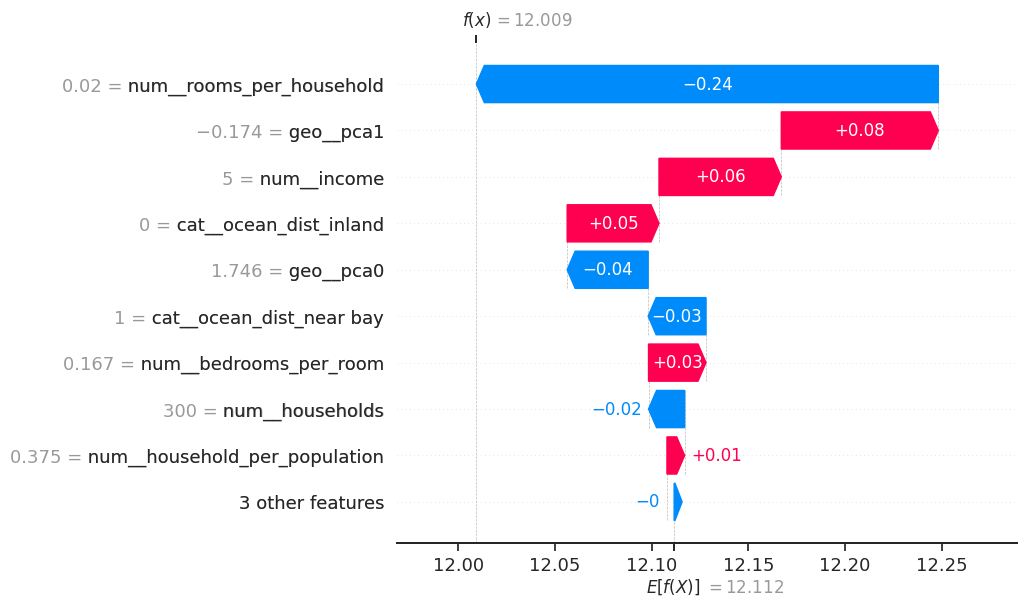


Precio base promedio : $181,979
Precio predicho      : $164,287


In [ ]:
# 1. Definir escenario de usuario hipotético (Tu entrada)
user_input = {
    'house_age'  : 15.0,
    'households' : 300.0,
    'income'     : 5.0,
    'rooms'      : 6.0,
    'bedrooms'   : 1.0,
    'population' : 800.0,
    'latitude'   : 37.88,
    'longitude'  : -122.23,
    'ocean_dist' : "near bay",   # o el valor que corresponda
}

# 2. Preparar datos (Ingeniería + Alineación)
input_raw = pd.DataFrame([user_input])
X_input = input_raw[FEATURES]

# 3. Predicción
best_model_name = tuning_df.iloc[0]['Model']
best_model_tuned = BEST_MODELS[best_model_name]
prediction = best_model_tuned.predict(X_input)[0]  # TransformedTargetRegressor ya aplica expm1
print(f"Precio estimado: ${prediction:,.0f}")

# 4. Explicación con SHAP (Configurado para mostrar los valores de entrada)
actual_model        = best_model_tuned.regressor_.named_steps['model']
X_input_transformed = best_model_tuned.regressor_.named_steps['prep'].transform(X_input)
feature_names_input = best_model_tuned.regressor_.named_steps['prep'].get_feature_names_out()

explainer_local   = shap.TreeExplainer(actual_model) # <-- para árboles, para otro algoritmo se usa otro explicador de SHAP
shap_values_local = explainer_local.shap_values(X_input_transformed)

# Definir base_val_local ANTES de usarlo
base_val_local = explainer_local.expected_value
if isinstance(base_val_local, (np.ndarray, list)):
    base_val_local = base_val_local[0]

exp = shap.Explanation(
    values        = shap_values_local[0],
    base_values   = base_val_local,
    data          = X_input_transformed[0],
    feature_names = feature_names_input
)

shap.plots.waterfall(exp)

# <-- Precio real traducido desde log
print(f"\nPrecio base promedio : ${np.expm1(base_val_local):,.0f}")
print(f"Precio predicho      : ${prediction:,.0f}")

In [ ]:
print(explainer_local.expected_value)
print(type(explainer_local.expected_value))

12.111651
<class 'numpy.float32'>
